# 279. Perfect Squares
https://leetcode.com/problems/perfect-squares/

## Complexity Comparison

| Approach | Time | Space | Description |
|----------|------|-------|-------------|
| BFS | O(n * sqrt(n)) | O(n) | BFS level = number of squares |
| **DP (Optimal)** | **O(n * sqrt(n))** | **O(n)** | Bottom-up DP |
| Math (Lagrange) | O(sqrt(n)) | O(1) | Use four-square theorem |

## Methodology

Use dynamic programming where `dp[i]` represents the minimum number of perfect squares that sum to `i`. For each number from 1 to n, try subtracting every perfect square `j*j <= i` and take the minimum: `dp[i] = min(dp[i - j*j] + 1)` for all valid j. Base case: `dp[0] = 0`.

## Solutions

### C#

In [ ]:
public class Solution {
    public int NumSquares(int n) {
        int[] dp = new int[n + 1];
        Array.Fill(dp, int.MaxValue);
        dp[0] = 0;
        for (int i = 1; i <= n; i++) {
            for (int j = 1; j * j <= i; j++) {
                dp[i] = Math.Min(dp[i], dp[i - j * j] + 1);
            }
        }
        return dp[n];
    }
}

### Python

In [ ]:
class Solution:
    def numSquares(self, n: int) -> int:
        dp = [float('inf')] * (n + 1)
        dp[0] = 0
        for i in range(1, n + 1):
            j = 1
            while j * j <= i:
                dp[i] = min(dp[i], dp[i - j * j] + 1)
                j += 1
        return dp[n]

### Go

In [ ]:
func numSquares(n int) int {
    dp := make([]int, n+1)
    for i := 1; i <= n; i++ {
        dp[i] = math.MaxInt32
        for j := 1; j*j <= i; j++ {
            dp[i] = min(dp[i], dp[i-j*j]+1)
        }
    }
    return dp[n]
}

### Rust

In [ ]:
impl Solution {
    pub fn num_squares(n: i32) -> i32 {
        let n = n as usize;
        let mut dp = vec![i32::MAX; n + 1];
        dp[0] = 0;
        for i in 1..=n {
            let mut j = 1;
            while j * j <= i {
                dp[i] = dp[i].min(dp[i - j * j] + 1);
                j += 1;
            }
        }
        dp[n]
    }
}

## Example Scenarios

### 1. Common Case — Three Equal Squares, n = 12
**Input:** `n = 12`
$12 = 4 + 4 + 4 = 2^2 + 2^2 + 2^2$. No decomposition uses fewer terms, so $dp[12] = 3$.

### 2. Slightly Complex — Two Distinct Squares, n = 13
**Input:** `n = 13`
$13 = 4 + 9 = 2^2 + 3^2$ mixes two *different* squares. $dp[13] = 2$, beating $9+1+1+1+1$.

### 3. Edge Case: Time — Larger n, n = 18
**Input:** `n = 18`
Every index $i$ tries all squares $j^2 \le i$, so work grows as $O(n\sqrt{n})$. $18 = 9 + 9$ gives $dp[18] = 2$.

### 4. Edge Case: Space — Minimal n = 1
**Input:** `n = 1`
The whole dp array is just $[0, 1]$. Since $1 = 1^2$, $dp[1] = 1$ — the smallest possible table.

### 5. Almost-Impossible but Plausible — Four-Square Floor, n = 7
**Input:** `n = 7`
By Lagrange's four-square theorem some integers need four squares. $7 = 4 + 1 + 1 + 1$ and nothing does better, so $dp[7] = 4$.


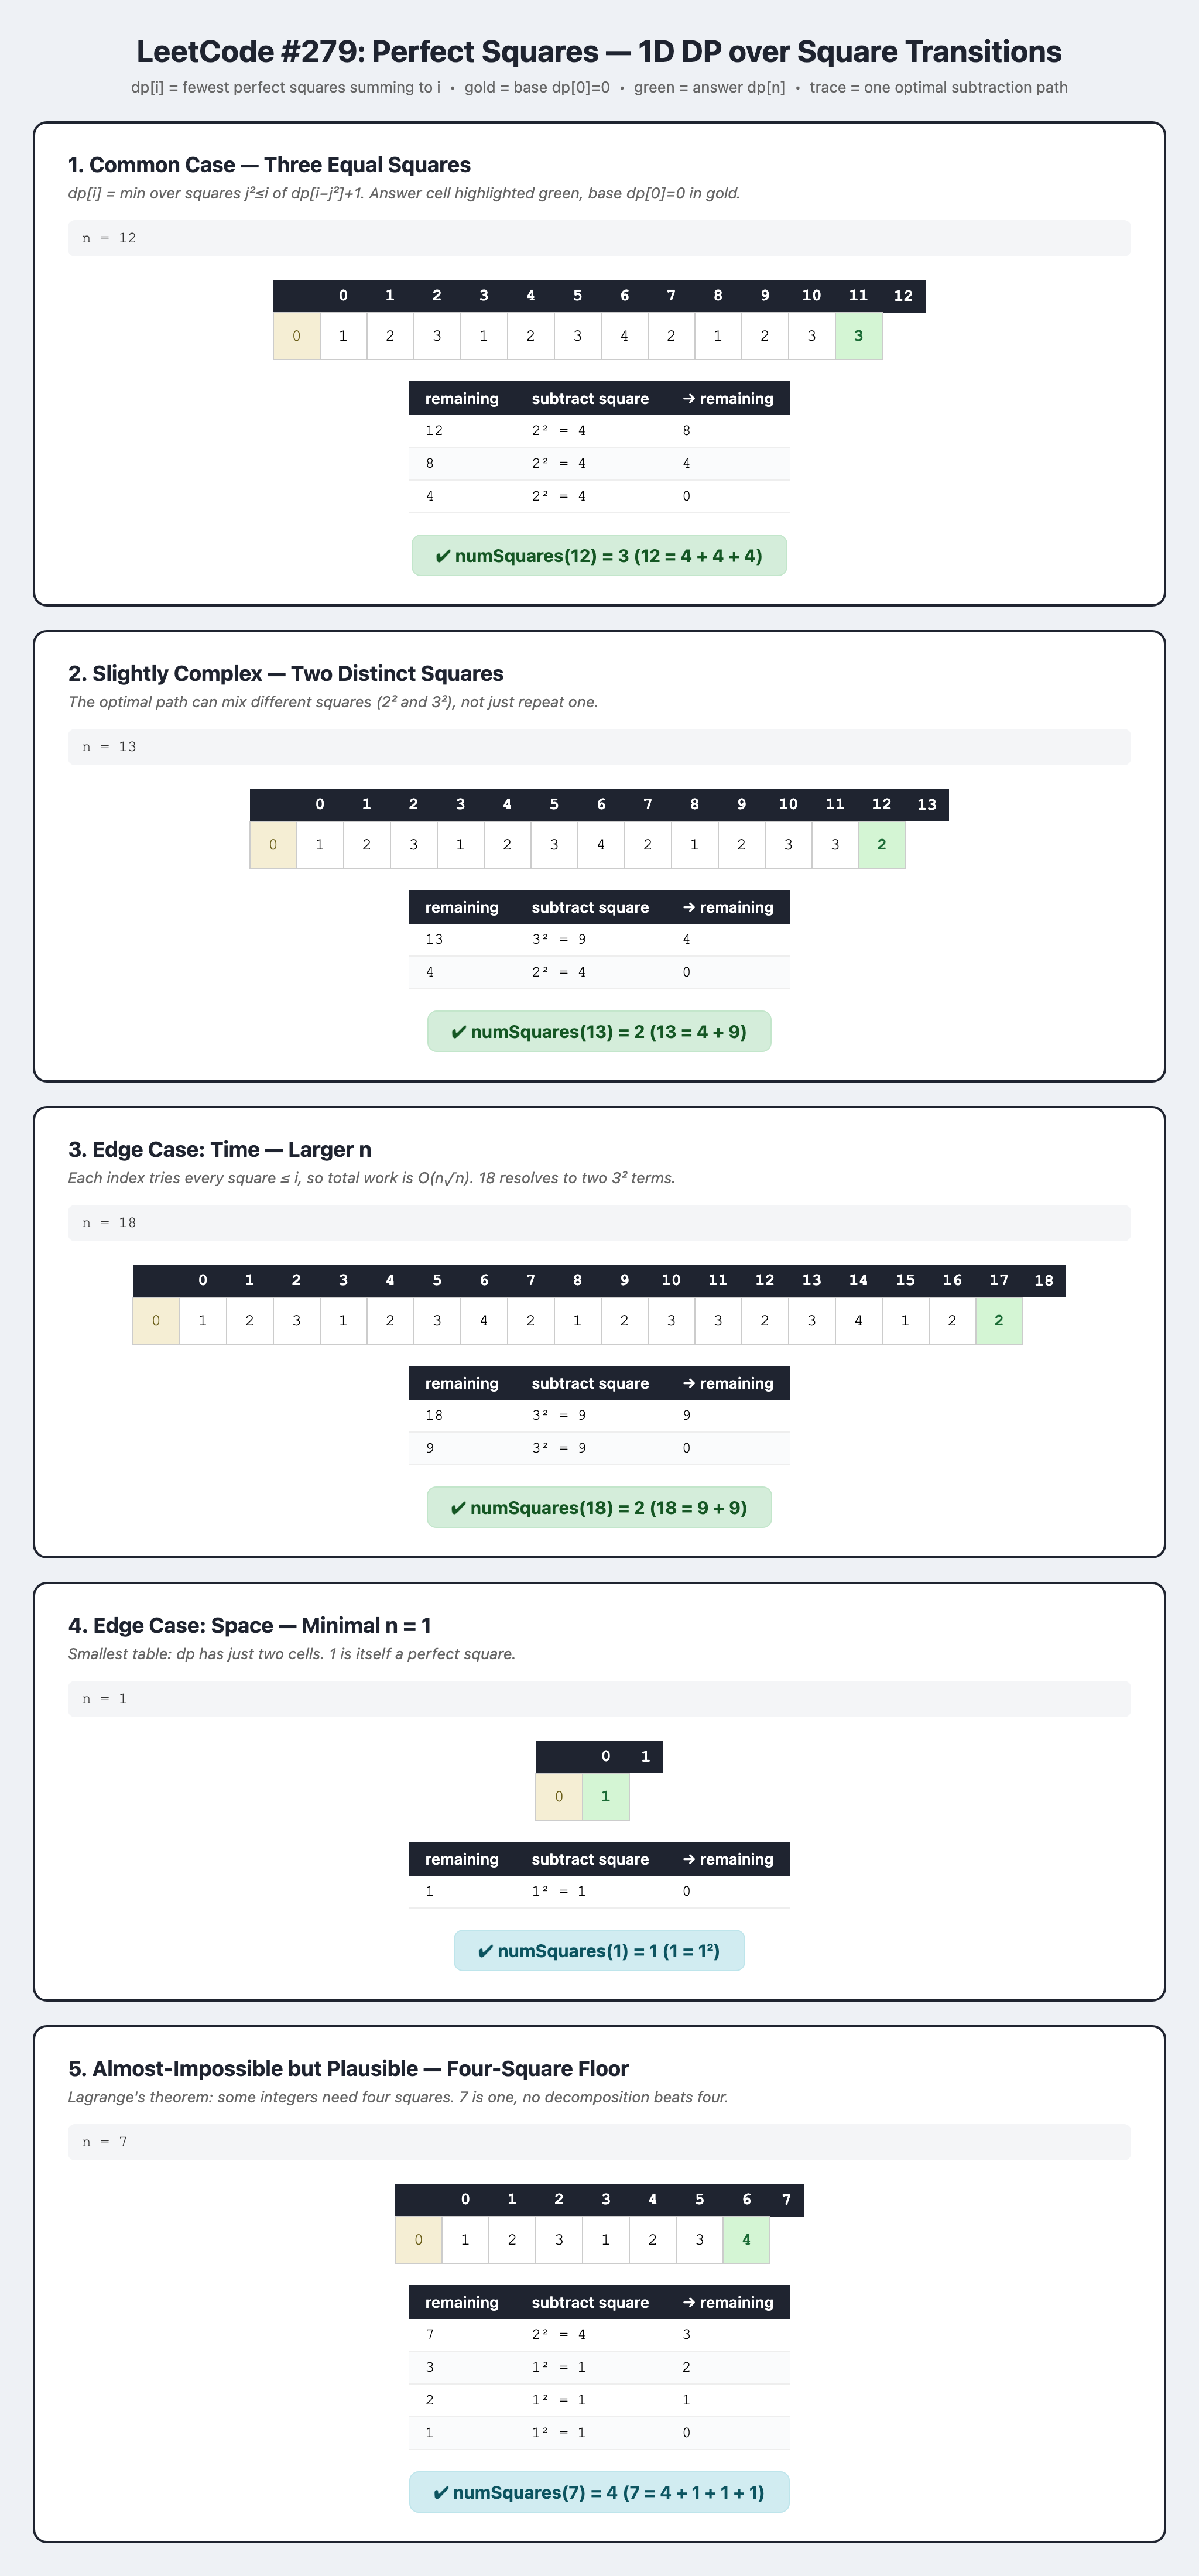